# EDA — Order Info
Exploratory analysis of `Data/Order Info.csv`: daily orders created and parcels delivered per SPX locker and parcel type.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})
COLORS = {"CB": "#1f77b4", "MP": "#ff7f0e", "WHS": "#2ca02c"}

df = pd.read_csv("../Data/Order Info.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%m/%d/%Y")
df.head()

,Date,SPX Locker ID,Parcel Type,Orders Created,Parcels Delivered
0,2024-09-12,4598,MP,5,22
1,2024-09-12,4599,MP,1,124
2,2024-09-13,4601,MP,0,10
3,2024-09-13,4600,MP,0,2
4,2024-09-13,4599,MP,0,39


## 1. Structure & data quality

In [2]:
print("Shape:", df.shape)
print("Date range:", df["Date"].min().date(), "to", df["Date"].max().date())
print("Unique dates:", df["Date"].nunique())
print("Unique lockers:", df["SPX Locker ID"].nunique())
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate (Date, Locker, Type) keys:", df.duplicated(["Date", "SPX Locker ID", "Parcel Type"]).sum())
df.dtypes

Shape: (151078, 5)
Date range: 2024-09-12 to 2026-02-23
Unique dates: 524
Unique lockers: 317

Missing values:
 Date                 0
SPX Locker ID        0
Parcel Type          0
Orders Created       0
Parcels Delivered    0
dtype: int64

Duplicate rows: 0
Duplicate (Date, Locker, Type) keys: 0


Date                 datetime64[us]
SPX Locker ID                 int64
Parcel Type                     str
Orders Created                int64
Parcels Delivered             int64
dtype: object

In [3]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
Date,151078,2025-10-07 15:33:09.176451,2024-09-12 00:00:00,2025-08-09 00:00:00,2025-10-22 00:00:00,2025-12-22 00:00:00,2026-02-23 00:00:00,NaN
SPX Locker ID,151078.0,5713.04221,4598.0,5432.0,5678.0,5755.0,6591.0,440.773029
Orders Created,151078.0,20.860628,0.0,6.0,15.0,28.0,343.0,20.588158
Parcels Delivered,151078.0,20.503502,0.0,5.0,14.0,29.0,359.0,21.780898


In [4]:
df.groupby("Parcel Type")[["Orders Created", "Parcels Delivered"]].describe().T

Parcel Type                        CB            MP           WHS
Orders Created    count  59658.000000  59003.000000  32417.000000
                  mean      33.351805     16.506601      5.797606
                  std       25.111702     11.450270      5.268907
                  min        0.000000      0.000000      0.000000
                  25%       16.000000      8.000000      2.000000
                  50%       29.000000     15.000000      4.000000
                  75%       45.000000     22.000000      8.000000
                  max      343.000000    188.000000    112.000000
Parcels Delivered count  59658.000000  59003.000000  32417.000000
                  mean      20.301100     20.264054     21.311812
                  std       21.796130     21.725946     21.834236
                  min        0.000000      0.000000      0.000000
                  25%        5.000000      5.000000      6.000000
                  50%       14.000000     14.000000     15.000000
                  75%       29.000000     29.000000     30.000000
                  max      325.000000    300.000000    359.000000

## 2. Parcel type mix

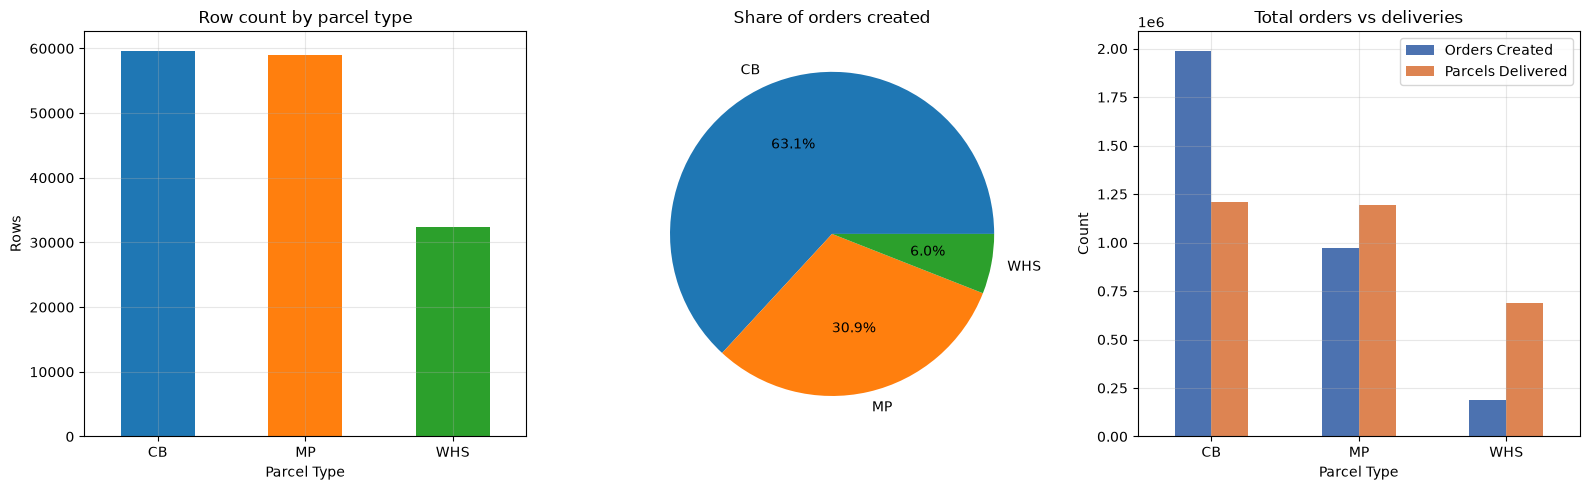

In [5]:
counts = df["Parcel Type"].value_counts()
totals = df.groupby("Parcel Type")[["Orders Created", "Parcels Delivered"]].sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
counts.plot.bar(ax=axes[0], color=[COLORS[t] for t in counts.index])
axes[0].set_title("Row count by parcel type"); axes[0].set_ylabel("Rows")

totals["Orders Created"].plot.pie(ax=axes[1], autopct="%1.1f%%", colors=[COLORS[t] for t in totals.index])
axes[1].set_title("Share of orders created"); axes[1].set_ylabel("")

totals.plot.bar(ax=axes[2], color=["#4c72b0", "#dd8452"])
axes[2].set_title("Total orders vs deliveries"); axes[2].set_ylabel("Count")
for ax in (axes[0], axes[2]): ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 3. Distributions

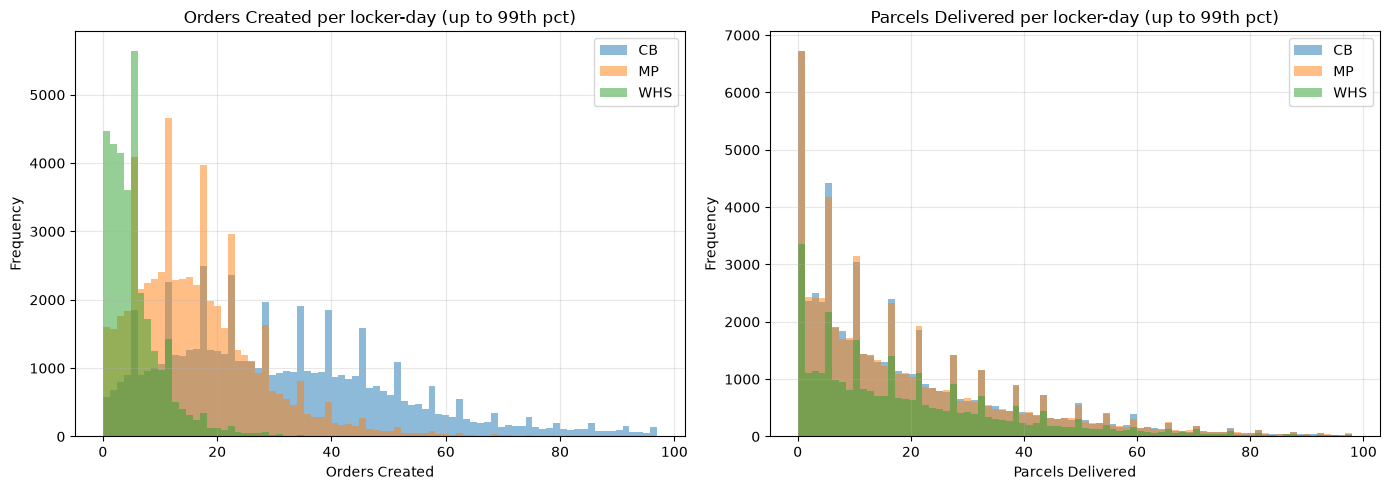

Share of zero values:
             Orders Created  Parcels Delivered
Parcel Type                                   
CB                    0.001              0.079
MP                    0.003              0.080
WHS                   0.011              0.074


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col in zip(axes, ["Orders Created", "Parcels Delivered"]):
    for t, g in df.groupby("Parcel Type"):
        ax.hist(g[col], bins=80, range=(0, df[col].quantile(0.99)), alpha=0.5, label=t, color=COLORS[t])
    ax.set_title(f"{col} per locker-day (up to 99th pct)"); ax.set_xlabel(col); ax.set_ylabel("Frequency"); ax.legend()
plt.tight_layout(); plt.show()

print("Share of zero values:")
print((df[["Orders Created", "Parcels Delivered"]] == 0).groupby(df["Parcel Type"]).mean().round(3))

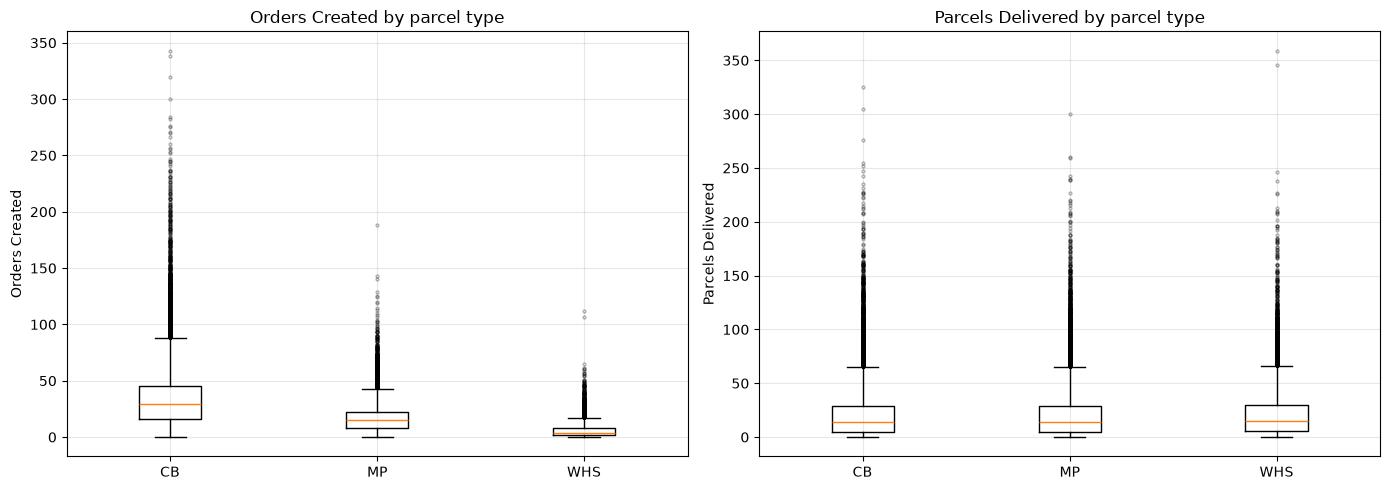

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
types = sorted(df["Parcel Type"].unique())
for ax, col in zip(axes, ["Orders Created", "Parcels Delivered"]):
    ax.boxplot([df.loc[df["Parcel Type"] == t, col] for t in types], tick_labels=types,
               flierprops=dict(markersize=2, alpha=0.3))
    ax.set_title(f"{col} by parcel type"); ax.set_ylabel(col)
plt.tight_layout(); plt.show()

## 4. Trends over time

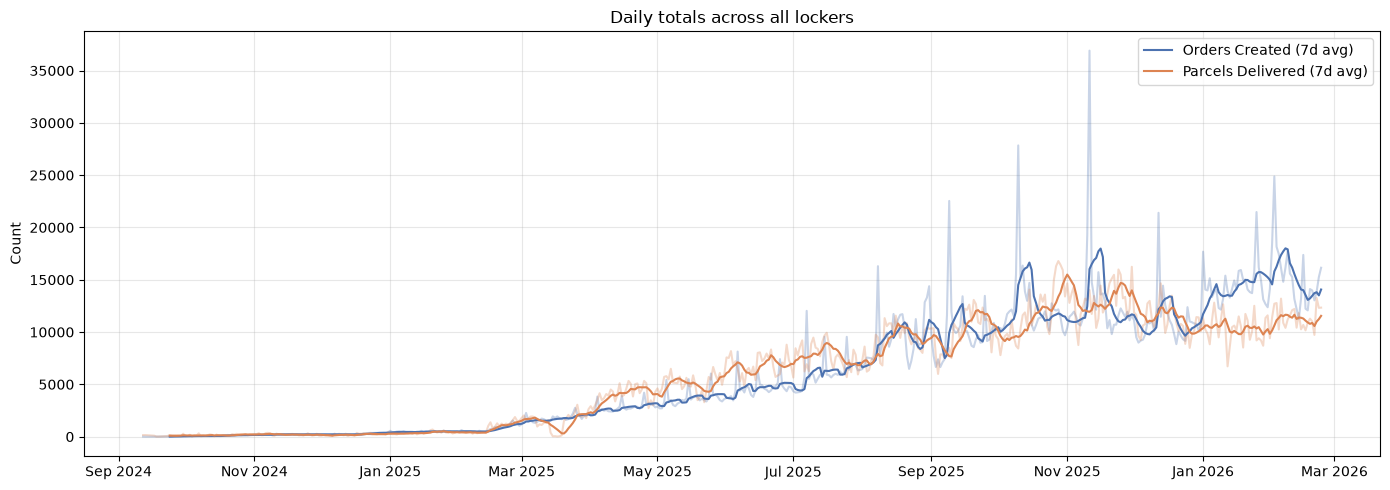

In [8]:
daily = df.groupby("Date")[["Orders Created", "Parcels Delivered"]].sum()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily.index, daily["Orders Created"], alpha=0.3, color="#4c72b0")
ax.plot(daily.index, daily["Parcels Delivered"], alpha=0.3, color="#dd8452")
ax.plot(daily.index, daily["Orders Created"].rolling(7).mean(), color="#4c72b0", label="Orders Created (7d avg)")
ax.plot(daily.index, daily["Parcels Delivered"].rolling(7).mean(), color="#dd8452", label="Parcels Delivered (7d avg)")
ax.set_title("Daily totals across all lockers"); ax.set_ylabel("Count"); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.show()

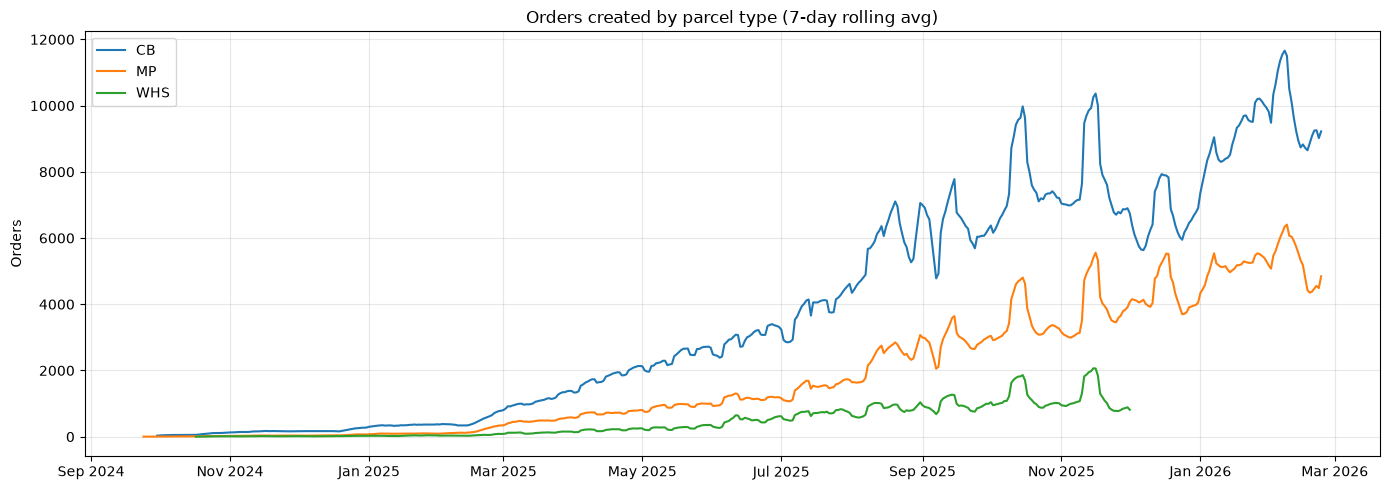

In [9]:
daily_type = df.pivot_table(index="Date", columns="Parcel Type", values="Orders Created", aggfunc="sum")

fig, ax = plt.subplots(figsize=(14, 5))
for t in daily_type.columns:
    ax.plot(daily_type.index, daily_type[t].rolling(7).mean(), label=t, color=COLORS[t])
ax.set_title("Orders created by parcel type (7-day rolling avg)"); ax.set_ylabel("Orders"); ax.legend()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.tight_layout(); plt.show()

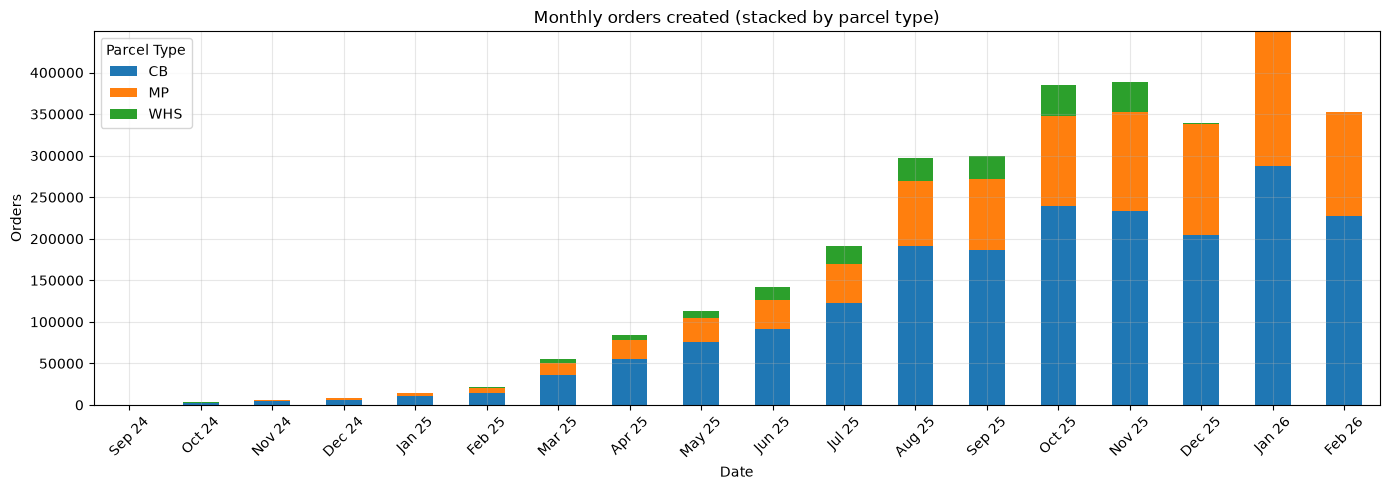

Note: first and last months may be partial.


In [10]:
monthly = df.set_index("Date").groupby("Parcel Type")["Orders Created"].resample("MS").sum().unstack(0)
monthly.index = monthly.index.strftime("%b %y")

ax = monthly.plot.bar(stacked=True, figsize=(14, 5), color=[COLORS[t] for t in monthly.columns])
ax.tick_params(axis="x", rotation=45)
ax.set_title("Monthly orders created (stacked by parcel type)"); ax.set_ylabel("Orders")
plt.tight_layout(); plt.show()
print("Note: first and last months may be partial.")

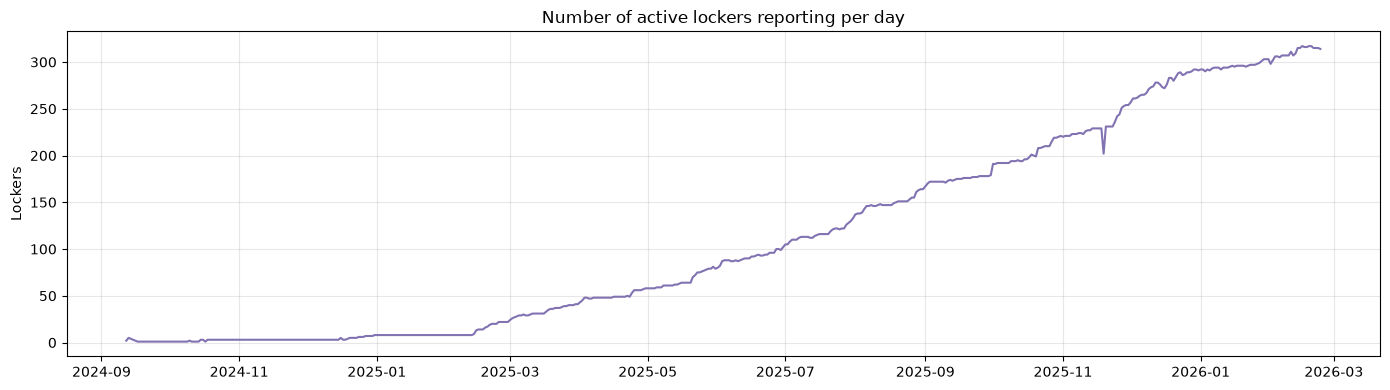

In [11]:
active = df.groupby("Date")["SPX Locker ID"].nunique()
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(active.index, active.values, color="#8172b2")
ax.set_title("Number of active lockers reporting per day"); ax.set_ylabel("Lockers")
plt.tight_layout(); plt.show()

## 5. Seasonality

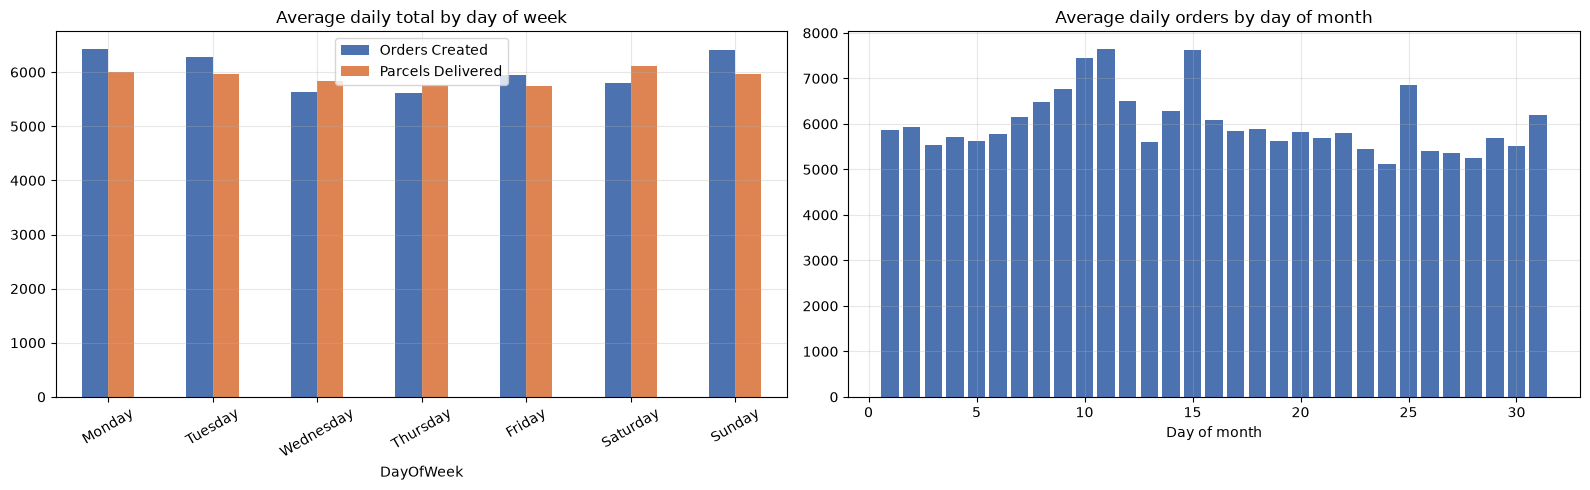

In [12]:
df["DayOfWeek"] = df["Date"].dt.day_name()
df["DayOfMonth"] = df["Date"].dt.day
dow_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

per_day = df.groupby(["Date", "DayOfWeek"])[["Orders Created", "Parcels Delivered"]].sum().reset_index()
dow = per_day.groupby("DayOfWeek")[["Orders Created", "Parcels Delivered"]].mean().reindex(dow_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
dow.plot.bar(ax=axes[0], color=["#4c72b0", "#dd8452"])
axes[0].set_title("Average daily total by day of week"); axes[0].tick_params(axis="x", rotation=30)

dom = df.groupby(["Date", "DayOfMonth"])["Orders Created"].sum().groupby("DayOfMonth").mean()
axes[1].bar(dom.index, dom.values, color="#4c72b0")
axes[1].set_title("Average daily orders by day of month")
axes[1].set_xlabel("Day of month")
plt.tight_layout(); plt.show()

In [13]:
top_days = daily["Orders Created"].nlargest(10)
print("Top 10 order days:")
print(top_days.to_frame().assign(Weekday=top_days.index.day_name()))

Top 10 order days:
            Orders Created  Weekday
Date                               
2025-11-11           36907  Tuesday
2025-10-10           27844   Friday
2026-02-02           24872   Monday
2025-09-09           22537  Tuesday
2026-01-25           21475   Sunday
2025-12-12           21402   Friday
2025-11-10           19314   Monday
2026-02-01           18444   Sunday
2026-02-03           18153  Tuesday
2026-02-08           17755   Sunday


## 6. Locker-level analysis

In [14]:
locker = df.groupby("SPX Locker ID").agg(
    orders=("Orders Created", "sum"),
    delivered=("Parcels Delivered", "sum"),
    days=("Date", "nunique"),
    first=("Date", "min"),
    last=("Date", "max"),
)
locker["avg_orders_per_day"] = locker["orders"] / locker["days"]
locker.sort_values("orders", ascending=False).head(10)

,orders,delivered,days,first,last,avg_orders_per_day
SPX Locker ID,,,,,,
4598,59204,31734,522,2024-09-12,2026-02-23,113.417625
5640,45059,20160,329,2025-03-30,2026-02-23,136.957447
4600,42391,29797,496,2024-09-13,2026-02-23,85.465726
4599,41574,29759,499,2024-09-12,2026-02-23,83.314629
5419,38411,20926,355,2025-03-05,2026-02-23,108.200000
4602,34498,25502,436,2024-09-13,2026-02-23,79.123853
5342,33342,21799,368,2025-02-21,2026-02-23,90.603261
4601,33233,26790,433,2024-09-13,2026-02-23,76.750577
5341,32898,20879,365,2025-02-24,2026-02-23,90.131507


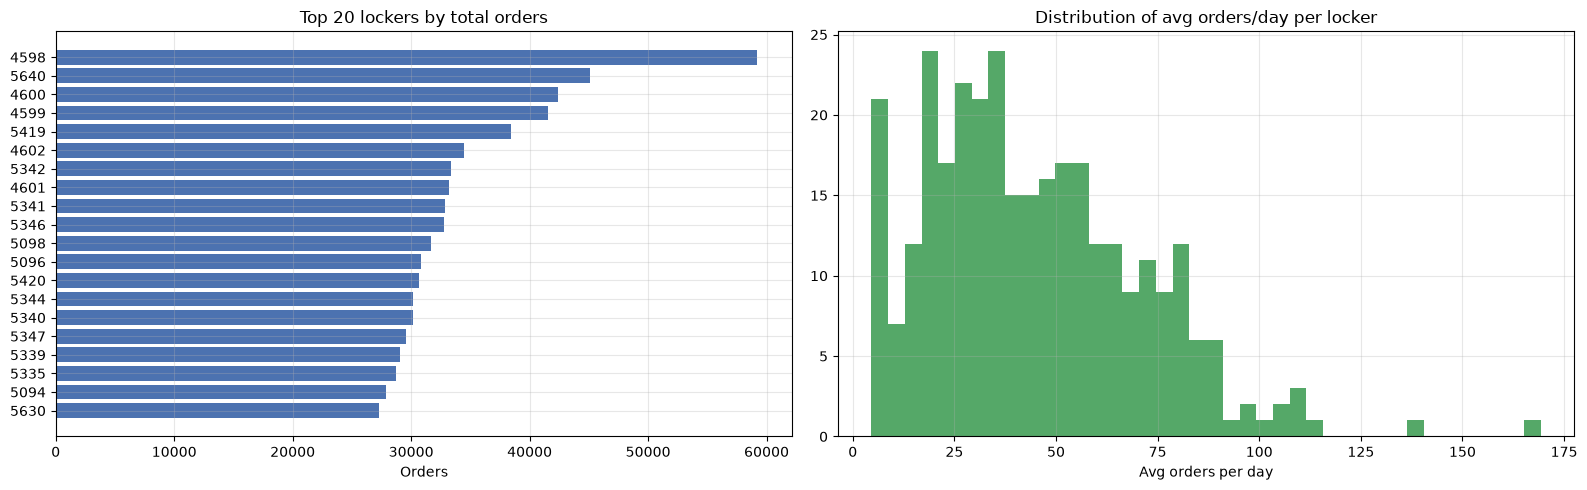

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top = locker["orders"].nlargest(20).sort_values()
axes[0].barh(top.index.astype(str), top.values, color="#4c72b0")
axes[0].set_title("Top 20 lockers by total orders"); axes[0].set_xlabel("Orders")

axes[1].hist(locker["avg_orders_per_day"], bins=40, color="#55a868")
axes[1].set_title("Distribution of avg orders/day per locker"); axes[1].set_xlabel("Avg orders per day")
plt.tight_layout(); plt.show()

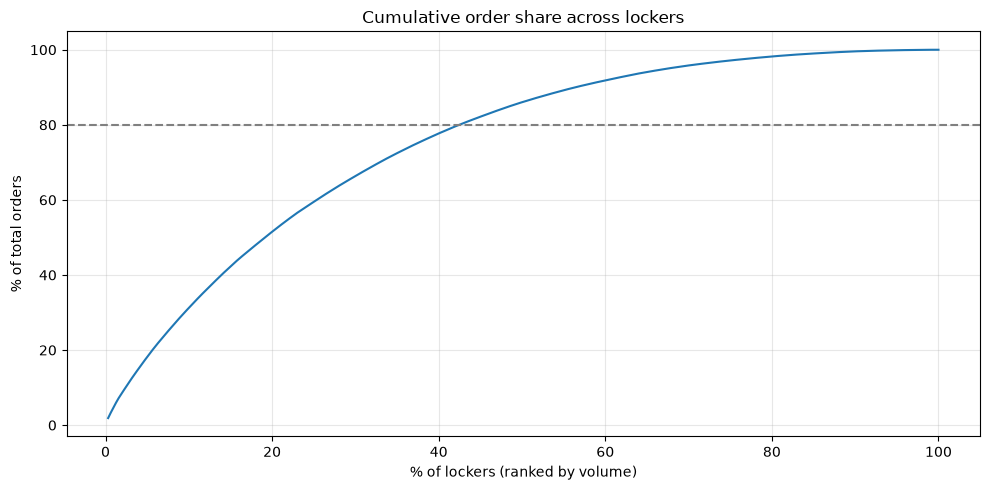

Top 20% of lockers handle 51.3% of orders


In [16]:
# Pareto: how concentrated is volume across lockers?
cum = locker["orders"].sort_values(ascending=False).cumsum() / locker["orders"].sum()
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values * 100)
ax.axhline(80, ls="--", c="grey")
ax.set_xlabel("% of lockers (ranked by volume)"); ax.set_ylabel("% of total orders")
ax.set_title("Cumulative order share across lockers")
plt.tight_layout(); plt.show()
print(f"Top 20% of lockers handle {cum.iloc[int(len(cum) * 0.2) - 1]:.1%} of orders")

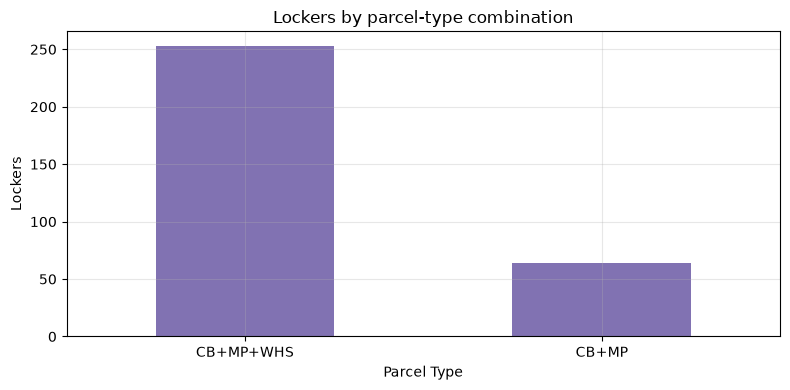

In [17]:
# Which parcel types does each locker handle?
mix = df.groupby("SPX Locker ID")["Parcel Type"].apply(lambda s: "+".join(sorted(s.unique())))
mix.value_counts().plot.bar(color="#8172b2", figsize=(8, 4), title="Lockers by parcel-type combination")
plt.xticks(rotation=0); plt.ylabel("Lockers"); plt.tight_layout(); plt.show()

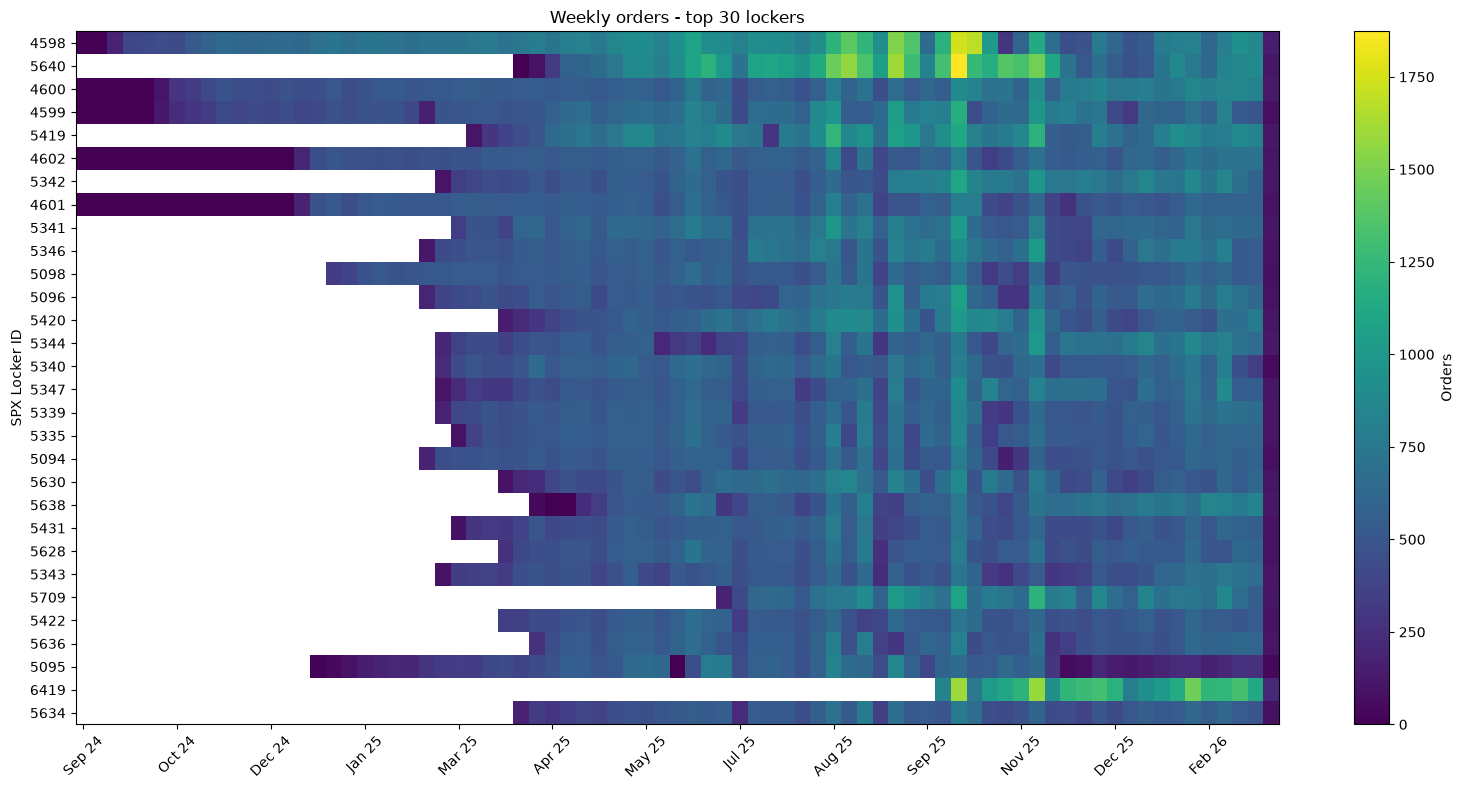

In [18]:
# Heatmap: weekly orders for top 30 lockers
top30 = locker["orders"].nlargest(30).index
wk = (df[df["SPX Locker ID"].isin(top30)].set_index("Date")
      .groupby("SPX Locker ID")["Orders Created"].resample("W").sum().unstack(1).reindex(top30))

fig, ax = plt.subplots(figsize=(16, 8))
im = ax.imshow(wk.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(len(wk.index))); ax.set_yticklabels(wk.index)
step = max(1, len(wk.columns) // 12)
ax.set_xticks(range(0, len(wk.columns), step))
ax.set_xticklabels([d.strftime("%b %y") for d in wk.columns[::step]], rotation=45)
ax.set_title("Weekly orders - top 30 lockers"); ax.set_ylabel("SPX Locker ID"); ax.grid(False)
fig.colorbar(im, ax=ax, label="Orders")
plt.tight_layout(); plt.show()

## 7. Orders created vs parcels delivered

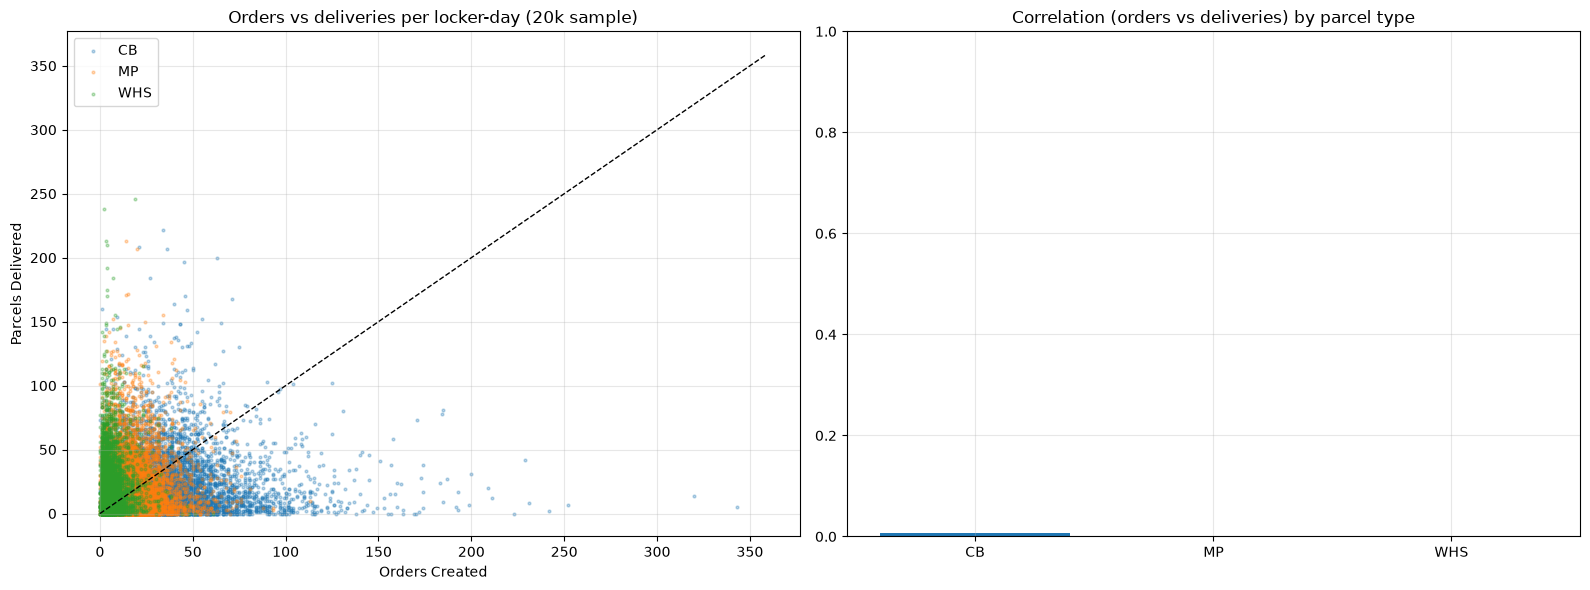

Overall correlation: -0.006


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sample = df.sample(min(20000, len(df)), random_state=42)
for t, g in sample.groupby("Parcel Type"):
    axes[0].scatter(g["Orders Created"], g["Parcels Delivered"], s=4, alpha=0.3, label=t, color=COLORS[t])
lim = df[["Orders Created", "Parcels Delivered"]].max().max()
axes[0].plot([0, lim], [0, lim], "k--", lw=1)
axes[0].set_xlabel("Orders Created"); axes[0].set_ylabel("Parcels Delivered")
axes[0].set_title("Orders vs deliveries per locker-day (20k sample)"); axes[0].legend()

corr = df.groupby("Parcel Type")[["Orders Created", "Parcels Delivered"]].corr().xs("Orders Created", level=1)["Parcels Delivered"]
axes[1].bar(corr.index, corr.values, color=[COLORS[t] for t in corr.index])
axes[1].set_ylim(0, 1); axes[1].set_title("Correlation (orders vs deliveries) by parcel type")
plt.tight_layout(); plt.show()
print("Overall correlation:", round(df["Orders Created"].corr(df["Parcels Delivered"]), 3))

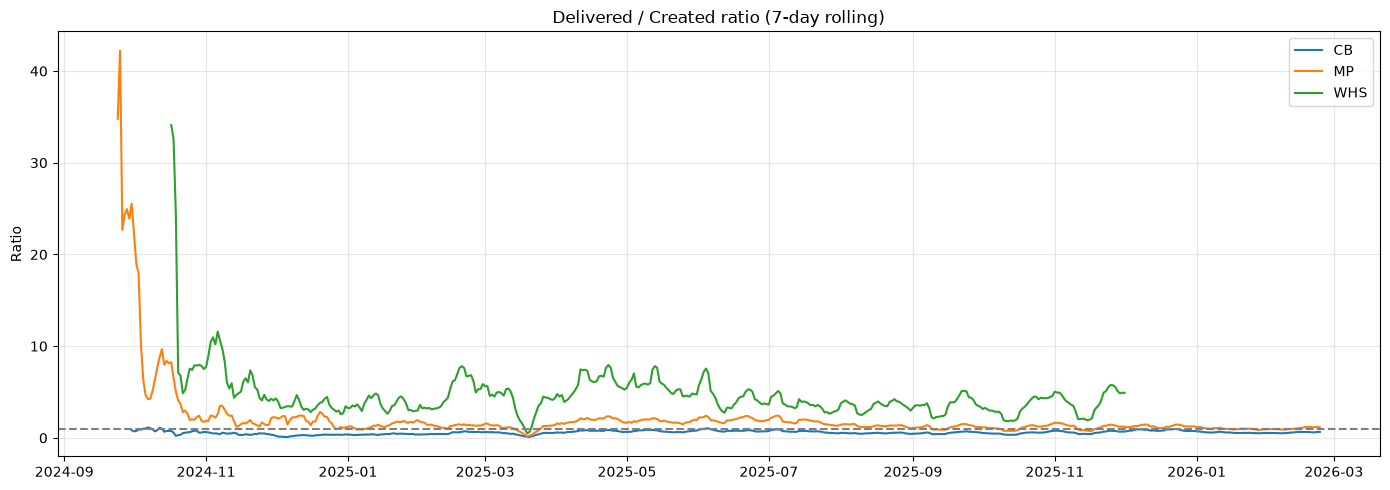

In [20]:
# Ratio of deliveries to orders created, 7-day rolling
deliv_type = df.pivot_table(index="Date", columns="Parcel Type", values="Parcels Delivered", aggfunc="sum")
ratio = deliv_type.rolling(7).sum() / daily_type.rolling(7).sum()

fig, ax = plt.subplots(figsize=(14, 5))
for t in ratio.columns:
    ax.plot(ratio.index, ratio[t], label=t, color=COLORS[t])
ax.axhline(1, ls="--", c="grey")
ax.set_title("Delivered / Created ratio (7-day rolling)"); ax.set_ylabel("Ratio"); ax.legend()
plt.tight_layout(); plt.show()

## 8. Outliers

In [21]:
# IQR-based upper outliers per parcel type
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s > q3 + 1.5 * (q3 - q1)).sum()

out = df.groupby("Parcel Type")[["Orders Created", "Parcels Delivered"]].agg(iqr_outliers)
out["rows"] = df["Parcel Type"].value_counts()
out

,Orders Created,Parcels Delivered,rows
Parcel Type,,,
CB,2104,2492,59658
MP,1623,2537,59003
WHS,1113,1402,32417


In [22]:
df.nlargest(10, "Orders Created")

,Date,SPX Locker ID,Parcel Type,Orders Created,Parcels Delivered,DayOfWeek,DayOfMonth
71658,2025-10-15,5640,CB,343,5,Wednesday,15
88245,2025-11-11,5419,CB,338,23,Tuesday,11
88181,2025-11-11,4598,CB,320,14,Tuesday,11
71581,2025-10-15,4598,CB,300,4,Wednesday,15
52377,2025-09-09,5640,CB,284,6,Tuesday,9
132759,2026-01-25,6419,CB,282,32,Sunday,25
52091,2025-09-09,4598,CB,276,9,Tuesday,9
88406,2025-11-11,5640,CB,275,1,Tuesday,11
42137,2025-08-19,5640,CB,271,3,Tuesday,19
68493,2025-10-10,6419,CB,270,6,Friday,10
